In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

import os
os.environ["PATH"] = "/global/common/software/nersc9/texlive/2024/bin/x86_64-linux:" + os.environ["PATH"]

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = "Times New Roman"

import healpy as hp
import pollux
import pyccl
import scipy.stats
from tqdm.auto import trange

import pickle
import sacc

import re


In [3]:
snapshots = np.arange(248, 400)

sim_relative_path = "HACC106_1024"
snap_sub_every_n = None # None for 400, 4 for 101, 8 for 51, 12 for 34 and 16 for 26
nshells_total = 400
if snap_sub_every_n is not None:
    nshells_total /= snap_sub_every_n
    nshells_total = int(nshells_total)+1
nside = 8192
sim_root = "/pscratch/sd/d/desc/HOS_Sims/"
save_dir_root = os.path.join(os.environ["CFS"], "lsst/shared/external/HACC-HOS-Y1/HOS_Sims")


In [4]:
dndz_flag="SRDv1_nz"

kappa_dir=dndz_flag

reader_dict = dict(
    path=os.path.join(sim_root, sim_relative_path),
    run_params="run/indat.params",
    snap_sub_every_n = snap_sub_every_n,
    snapshots=snapshots,
)
reader = pollux.reader.HACCLightconeReader(**reader_dict)
cosmo = reader.cosmo

builder_dict = dict(
    nside=nside,
    save_dir=os.path.join(
        save_dir_root,
        sim_relative_path,
        f"shells_z{nshells_total}_lightcone_insitu_nside"+str(nside)+"/",
    ),
    dtype=np.float32,
    wsp_dir=save_dir_root,
)

builder = pollux.shells.SnapshotShellBuilderHeitmann(reader, **builder_dict)

if dndz_flag == "SRDv1_nz":
    dndz = np.loadtxt("data/"+dndz_flag+".txt")

lensing_dict_srd = dict(
    nzs=[(dndz[:, 0], dndz[:, i]) for i in range(1, 4)],
    kappa_dir=kappa_dir,
    wsp_dir=save_dir_root,
    sigma_e=0.3,
)
lensing = pollux.lensing.BornLensingBuilder(builder, **lensing_dict_srd)

Cls_th=lensing.predict_cls(auto_only=False,error_bars=True,stacked=True)


*** HACC reader ***
  - Reading parameter file at /pscratch/sd/d/desc/HOS_Sims/HACC106_1024/run/indat.params
  - Cosmology <pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0x6e4bd97daaf4f19f
*** Map builder (shell_hacc_seed12345) ***
  - Number of maps = 152
  - Maps saved to /global/cfs/cdirs/lsst/shared/external/HACC-HOS-Y1/HOS_Sims/HACC106_1024/shells_z400_lightcone_insitu_nside8192/
  - Box size = 845.07 Mpc
*** Map builder (kappa_hacc_seed12345) ***
  - Number of maps = 3
  - Maps saved to /global/cfs/cdirs/lsst/shared/external/HACC-HOS-Y1/HOS_Sims/HACC106_1024/shells_z400_lightcone_insitu_nside8192/SRDv1_nz
Loading workspace in /global/cfs/cdirs/lsst/shared/external/HACC-HOS-Y1/HOS_Sims/wsp_nside8192.wsp


/global/u1/j/jmena/pollux_root/pollux/pollux/shells.py:157: UserWarning: Some shells are deeper than the simulation box!
Shell 0 (0.00<z<0.25) has width 1000.41 Mpc

  warnings.warn(message)


[predict_cls]:   0%|          | 0/6 [00:00<?, ?it/s]

In [5]:
N_part = 1024

if N_part == 1024:
    sim_list = ["HACC091_1024", "HACC106_1024"]
    nshells_list_a = [26, 34, 51, 101]
    seed_list = ["12345"]

path = f"rotflip"
extra_info_a = "method\ (1)"

Cls_dict_a = {}

for i_sim in sim_list:
    for i_nshells in nshells_list_a:
        for i_seed in seed_list:
            fits_file = os.path.join(
                save_dir_root, i_sim, 
                f"shells_z{i_nshells}_{path}_nside{nside}",
                kappa_dir, f"kappa_hacc_seed{i_seed}_nside{nside}_cls.fits"
            )
            
            if not os.path.exists(fits_file):
                print(f"File not found: {fits_file}")
                continue
            
            Cls = {}
            s = sacc.Sacc.load_fits(fits_file)
            
            for t1, t2 in s.get_tracer_combinations():
                ell, cell = np.column_stack([s.get_ell_cl("galaxy_convergence_cl", t1, t2)])
                t1_n = re.search(r'\d+', t1).group()
                t2_n = re.search(r'\d+', t2).group()
                Cls[f"({t1_n}, {t2_n})"] = np.column_stack([ell, cell])

            key = (N_part, i_sim, i_seed, i_nshells, extra_info_a)
            Cls_dict_a[key] = Cls
            print(f"Stored Cls for {key}")


Stored Cls for (1024, 'HACC091_1024', '12345', 26, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', '12345', 34, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', '12345', 51, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', '12345', 101, 'method\\ (1)')
Stored Cls for (1024, 'HACC106_1024', '12345', 26, 'method\\ (1)')
Stored Cls for (1024, 'HACC106_1024', '12345', 34, 'method\\ (1)')
Stored Cls for (1024, 'HACC106_1024', '12345', 51, 'method\\ (1)')
Stored Cls for (1024, 'HACC106_1024', '12345', 101, 'method\\ (1)')


In [6]:
N_part = 1024

if N_part == 1024:
    sim_list = ["HACC091_1024", "HACC106_1024"]
    nshells_list_b = [26, 34, 51, 101, 201, 400]
    seed_list = ["12345"]

path = f"lightcone_insitu"
extra_info_b = "method\ (3)"

Cls_dict_b = {}

for i_sim in sim_list:
    for i_nshells in nshells_list_b:
        for i_seed in seed_list:
            fits_file = os.path.join(
                save_dir_root, i_sim, 
                f"shells_z{i_nshells}_{path}_nside{nside}",
                kappa_dir, f"kappa_hacc_seed{i_seed}_nside{nside}_cls.fits"
            )
            
            if not os.path.exists(fits_file):
                print(f"File not found: {fits_file}")
                continue
            
            Cls = {}
            s = sacc.Sacc.load_fits(fits_file)
            
            for t1, t2 in s.get_tracer_combinations():
                ell, cell = np.column_stack([s.get_ell_cl("galaxy_convergence_cl", t1, t2)])
                t1_n = re.search(r'\d+', t1).group()
                t2_n = re.search(r'\d+', t2).group()
                Cls[f"({t1_n}, {t2_n})"] = np.column_stack([ell, cell])

            key = (N_part, i_sim, i_seed, i_nshells, extra_info_b)
            Cls_dict_b[key] = Cls
            print(f"Stored Cls for {key}")


Stored Cls for (1024, 'HACC091_1024', '12345', 26, 'method\\ (3)')
Stored Cls for (1024, 'HACC091_1024', '12345', 34, 'method\\ (3)')
Stored Cls for (1024, 'HACC091_1024', '12345', 51, 'method\\ (3)')
Stored Cls for (1024, 'HACC091_1024', '12345', 101, 'method\\ (3)')
Stored Cls for (1024, 'HACC091_1024', '12345', 201, 'method\\ (3)')
Stored Cls for (1024, 'HACC091_1024', '12345', 400, 'method\\ (3)')
Stored Cls for (1024, 'HACC106_1024', '12345', 26, 'method\\ (3)')
Stored Cls for (1024, 'HACC106_1024', '12345', 34, 'method\\ (3)')
Stored Cls for (1024, 'HACC106_1024', '12345', 51, 'method\\ (3)')
Stored Cls for (1024, 'HACC106_1024', '12345', 101, 'method\\ (3)')
Stored Cls for (1024, 'HACC106_1024', '12345', 201, 'method\\ (3)')
Stored Cls for (1024, 'HACC106_1024', '12345', 400, 'method\\ (3)')


In [7]:
from plots_methods import compute_averages

compute_averages(data_dict=Cls_dict_a, sim_list=sim_list, seed_list=seed_list, nshells_list=nshells_list_a, N_part=N_part, extra_info=extra_info_a)
compute_averages(data_dict=Cls_dict_b, sim_list=sim_list, seed_list=seed_list, nshells_list=nshells_list_b, N_part=N_part, extra_info=extra_info_b)

Cls_dict = {**Cls_dict_a, **Cls_dict_b}


Stored avg over seeds for (1024, 'HACC091_1024', 'avg', 26, 'method\\ (1)')
Stored std over seeds for (1024, 'HACC091_1024', 'std', 26, 'method\\ (1)')
Stored avg over seeds for (1024, 'HACC091_1024', 'avg', 34, 'method\\ (1)')
Stored std over seeds for (1024, 'HACC091_1024', 'std', 34, 'method\\ (1)')
Stored avg over seeds for (1024, 'HACC091_1024', 'avg', 51, 'method\\ (1)')
Stored std over seeds for (1024, 'HACC091_1024', 'std', 51, 'method\\ (1)')
Stored avg over seeds for (1024, 'HACC091_1024', 'avg', 101, 'method\\ (1)')
Stored std over seeds for (1024, 'HACC091_1024', 'std', 101, 'method\\ (1)')
Stored avg over seeds for (1024, 'HACC106_1024', 'avg', 26, 'method\\ (1)')
Stored std over seeds for (1024, 'HACC106_1024', 'std', 26, 'method\\ (1)')
Stored avg over seeds for (1024, 'HACC106_1024', 'avg', 34, 'method\\ (1)')
Stored std over seeds for (1024, 'HACC106_1024', 'std', 34, 'method\\ (1)')
Stored avg over seeds for (1024, 'HACC106_1024', 'avg', 51, 'method\\ (1)')
Stored std

In [8]:
def average_z(zbin):

    return np.trapz(lensing.nzs[zbin][0]*lensing.nzs[zbin][1], lensing.nzs[zbin][0])

def ell_min(zbin):
    
    theta_max = reader.boxsize()/cosmo.comoving_angular_distance(1/(1+average_z(zbin)))
    
    return np.pi/theta_max

ell_min_dict = {zbin: ell_min(zbin) for zbin in range(3)}


In [9]:
list_plot = [
    (N_part, "avg", "avg", 26, extra_info_b),
    (N_part, "avg", "avg", 34, extra_info_b),
    (N_part, "avg", "avg", 51, extra_info_b),
    (N_part, "avg", "avg", 101, extra_info_b),
    (N_part, "avg", "avg", 201, extra_info_b),
    (N_part, "avg", "avg", 400, extra_info_b),
]


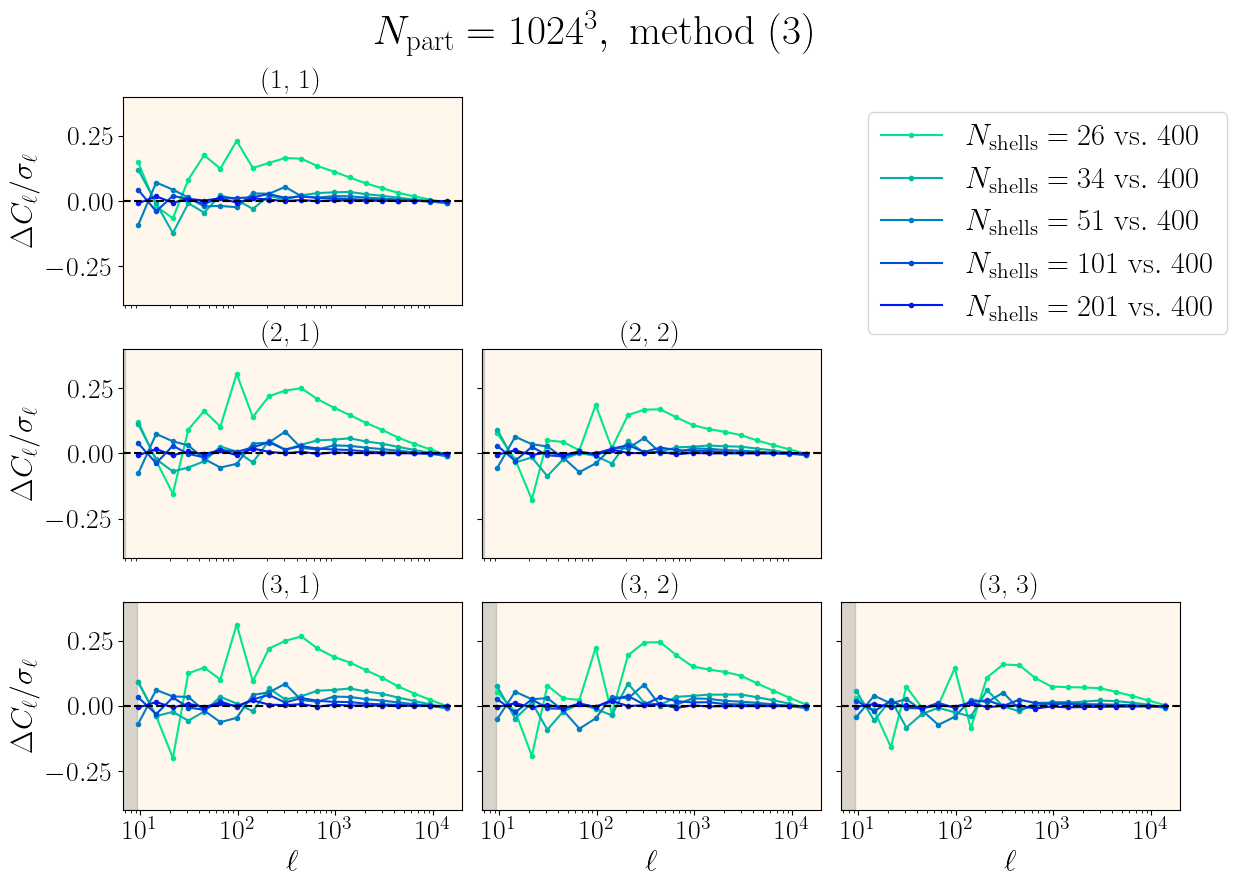

In [10]:
map_list = np.arange(0, 3)

from plots_methods import plot_Cls_kappa

# Plot 4
plot_Cls_kappa(4, map_list, Cls_dict, Cls_th, ell_min_dict, list_plot, filename_extra="method3", ylim=[-0.4, 0.4])


In [11]:
list_plot = [
    (N_part, "avg", "avg", 26, extra_info_a),
    (N_part, "avg", "avg", 34, extra_info_a),
    (N_part, "avg", "avg", 51, extra_info_a),
    (N_part, "avg", "avg", 101, extra_info_a),
    
    (N_part, "avg", "avg", 26, extra_info_b),
    (N_part, "avg", "avg", 34, extra_info_b),
    (N_part, "avg", "avg", 51, extra_info_b),
    (N_part, "avg", "avg", 101, extra_info_b),
]


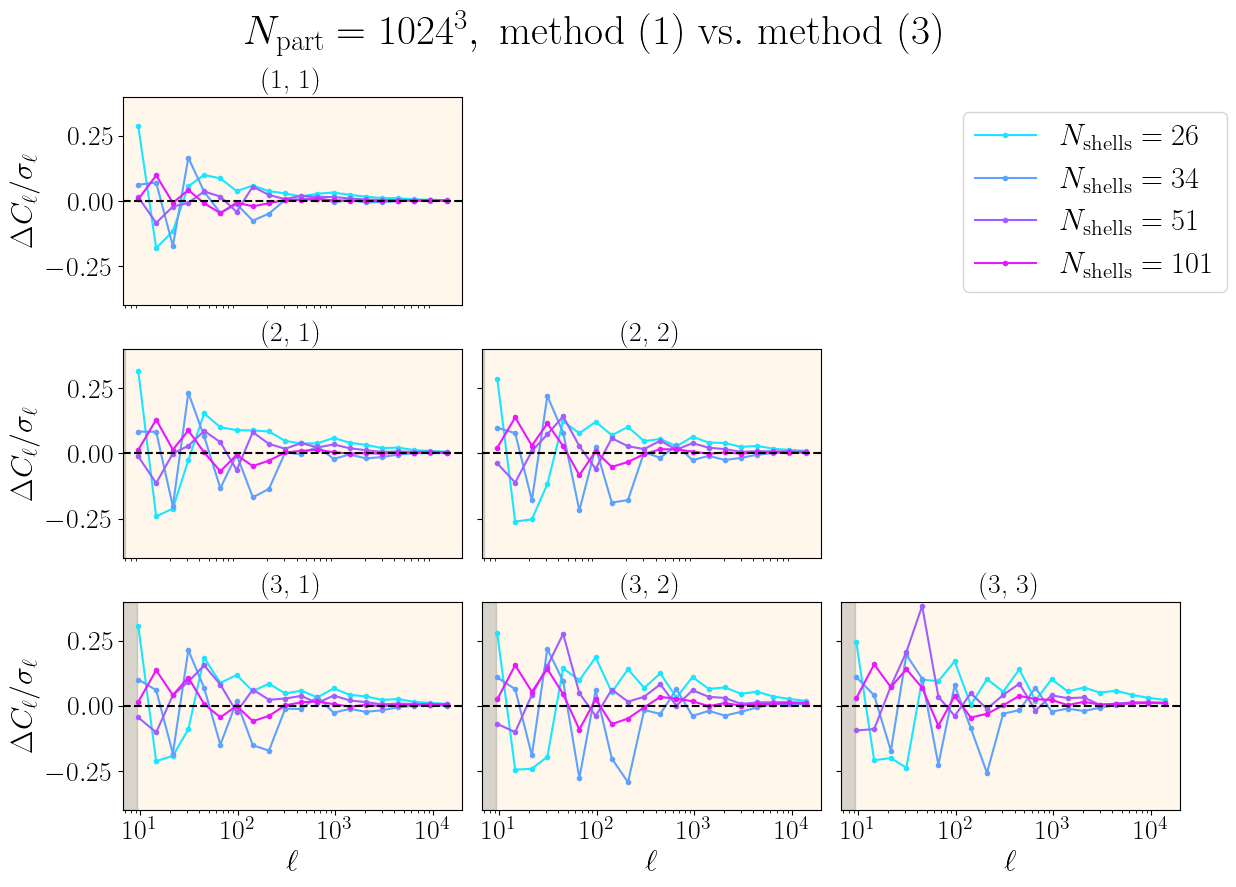

In [12]:
map_list = np.arange(0, 3)

from plots_methods import plot_Cls_kappa

# Plot 5
plot_Cls_kappa(5, map_list, Cls_dict, Cls_th, ell_min_dict, list_plot, filename_extra="method1_vs_method3", ylim=[-0.4, 0.4])


In [13]:
list_chi2 = [
    (N_part, "avg", "avg", 26, extra_info_a),
    (N_part, "avg", "avg", 34, extra_info_a),
    (N_part, "avg", "avg", 51, extra_info_a),
    (N_part, "avg", "avg", 101, extra_info_a),
]

Cls_dict_chi2 = {key: Cls_dict[key] for key in list_chi2 if key in Cls_dict}

for key, value in Cls_dict_chi2.items():
    value["concatenated"] = np.concatenate([
        value[f"({j}, {i})"][:, 1][ell >= max(ell_min_dict[i], ell_min_dict[j])]
        for i in range(len(lensing.nzs))
        for j in range(i, len(lensing.nzs))
    ])

Cls_th_concatenated = np.concatenate([
    Cls_th[1][(j, i)][ell >= max(ell_min_dict[i], ell_min_dict[j])]
    for i in range(len(lensing.nzs))
    for j in range(i, len(lensing.nzs))
])

sigmals_th_concatenated = np.concatenate([
    Cls_th[2][(j, i)][ell >= max(ell_min_dict[i], ell_min_dict[j])]
    for i in range(len(lensing.nzs))
    for j in range(i, len(lensing.nzs))
])

included_indices = []
offset = 0

for i in range(len(lensing.nzs)):
    for j in range(i, len(lensing.nzs)):
        mask = ell >= max(ell_min_dict[i], ell_min_dict[j])
        n_kept = np.sum(mask)
        included_indices.extend(np.arange(offset, offset + len(mask))[mask])
        offset += len(mask)

cov_cut = Cls_th[4][np.ix_(included_indices, included_indices)]

print("This has to be zero:")
print((sigmals_th_concatenated - np.sqrt(np.diag(cov_cut))).max())

print("")
print("chi2 vs theory")

for key, value in Cls_dict_chi2.items():
    delta = value["concatenated"] - Cls_th_concatenated
    chi2 = delta @ np.linalg.inv(cov_cut) @ delta
    print([key, round(chi2, 2)])

print("")
print("Pairwise chi2")

for key_1, value_1 in Cls_dict_chi2.items():
    for key_2, value_2 in Cls_dict_chi2.items():
        if int(key_2[3]) > int(key_1[3]) and int(key_2[3]) == 101:
            delta = value_1["concatenated"] - value_2["concatenated"]
            chi2 = delta @ np.linalg.inv(cov_cut) @ delta
            print([key_1, key_2, round(chi2, 2)])


This has to be zero:
0.0

chi2 vs theory
[(1024, 'avg', 'avg', 26, 'method\\ (1)'), 9.64]
[(1024, 'avg', 'avg', 34, 'method\\ (1)'), 8.67]
[(1024, 'avg', 'avg', 51, 'method\\ (1)'), 8.93]
[(1024, 'avg', 'avg', 101, 'method\\ (1)'), 8.46]

Pairwise chi2
[(1024, 'avg', 'avg', 26, 'method\\ (1)'), (1024, 'avg', 'avg', 101, 'method\\ (1)'), 2.8]
[(1024, 'avg', 'avg', 34, 'method\\ (1)'), (1024, 'avg', 'avg', 101, 'method\\ (1)'), 0.41]
[(1024, 'avg', 'avg', 51, 'method\\ (1)'), (1024, 'avg', 'avg', 101, 'method\\ (1)'), 0.33]


In [14]:
list_chi2 = [
    (N_part, "avg", "avg", 26, extra_info_b),
    (N_part, "avg", "avg", 34, extra_info_b),
    (N_part, "avg", "avg", 51, extra_info_b),
    (N_part, "avg", "avg", 101, extra_info_b),
    (N_part, "avg", "avg", 201, extra_info_b),
    (N_part, "avg", "avg", 400, extra_info_b),
]

Cls_dict_chi2 = {key: Cls_dict[key] for key in list_chi2 if key in Cls_dict}

for key, value in Cls_dict_chi2.items():
    value["concatenated"] = np.concatenate([
        value[f"({j}, {i})"][:, 1][ell >= max(ell_min_dict[i], ell_min_dict[j])]
        for i in range(len(lensing.nzs))
        for j in range(i, len(lensing.nzs))
    ])

Cls_th_concatenated = np.concatenate([
    Cls_th[1][(j, i)][ell >= max(ell_min_dict[i], ell_min_dict[j])]
    for i in range(len(lensing.nzs))
    for j in range(i, len(lensing.nzs))
])

sigmals_th_concatenated = np.concatenate([
    Cls_th[2][(j, i)][ell >= max(ell_min_dict[i], ell_min_dict[j])]
    for i in range(len(lensing.nzs))
    for j in range(i, len(lensing.nzs))
])

included_indices = []
offset = 0

for i in range(len(lensing.nzs)):
    for j in range(i, len(lensing.nzs)):
        mask = ell >= max(ell_min_dict[i], ell_min_dict[j])
        n_kept = np.sum(mask)
        included_indices.extend(np.arange(offset, offset + len(mask))[mask])
        offset += len(mask)

cov_cut = Cls_th[4][np.ix_(included_indices, included_indices)]

print("This has to be zero:")
print((sigmals_th_concatenated - np.sqrt(np.diag(cov_cut))).max())

print("")
print("chi2 vs theory")

for key, value in Cls_dict_chi2.items():
    delta = value["concatenated"] - Cls_th_concatenated
    chi2 = delta @ np.linalg.inv(cov_cut) @ delta
    print([key, round(chi2, 2)])

print("")
print("Pairwise chi2")

for key_1, value_1 in Cls_dict_chi2.items():
    for key_2, value_2 in Cls_dict_chi2.items():
        delta = value_1["concatenated"] - value_2["concatenated"]
        chi2 = delta @ np.linalg.inv(cov_cut) @ delta
        print([key_1, key_2, round(chi2, 2)])


This has to be zero:
0.0

chi2 vs theory
[(1024, 'avg', 'avg', 26, 'method\\ (3)'), 8.89]
[(1024, 'avg', 'avg', 34, 'method\\ (3)'), 9.05]
[(1024, 'avg', 'avg', 51, 'method\\ (3)'), 9.09]
[(1024, 'avg', 'avg', 101, 'method\\ (3)'), 9.01]
[(1024, 'avg', 'avg', 201, 'method\\ (3)'), 9.09]
[(1024, 'avg', 'avg', 400, 'method\\ (3)'), 9.1]

Pairwise chi2
[(1024, 'avg', 'avg', 26, 'method\\ (3)'), (1024, 'avg', 'avg', 26, 'method\\ (3)'), 0.0]
[(1024, 'avg', 'avg', 26, 'method\\ (3)'), (1024, 'avg', 'avg', 34, 'method\\ (3)'), 1.0]
[(1024, 'avg', 'avg', 26, 'method\\ (3)'), (1024, 'avg', 'avg', 51, 'method\\ (3)'), 1.12]
[(1024, 'avg', 'avg', 26, 'method\\ (3)'), (1024, 'avg', 'avg', 101, 'method\\ (3)'), 1.11]
[(1024, 'avg', 'avg', 26, 'method\\ (3)'), (1024, 'avg', 'avg', 201, 'method\\ (3)'), 1.25]
[(1024, 'avg', 'avg', 26, 'method\\ (3)'), (1024, 'avg', 'avg', 400, 'method\\ (3)'), 1.26]
[(1024, 'avg', 'avg', 34, 'method\\ (3)'), (1024, 'avg', 'avg', 26, 'method\\ (3)'), 1.0]
[(1024, 'av

In [15]:
list_chi2 = [
    (N_part, "avg", "avg", 26, extra_info_a),
    (N_part, "avg", "avg", 34, extra_info_a),
    (N_part, "avg", "avg", 51, extra_info_a),
    (N_part, "avg", "avg", 101, extra_info_a),
]

Cls_dict_chi2_a = {key: Cls_dict[key] for key in list_chi2 if key in Cls_dict}

list_chi2 = [
    (N_part, "avg", "avg", 26, extra_info_b),
    (N_part, "avg", "avg", 34, extra_info_b),
    (N_part, "avg", "avg", 51, extra_info_b),
    (N_part, "avg", "avg", 101, extra_info_b),
]

Cls_dict_chi2_b = {key: Cls_dict[key] for key in list_chi2 if key in Cls_dict}

for key, value in Cls_dict_chi2_a.items():
    value["concatenated"] = np.concatenate([
        value[f"({j}, {i})"][:, 1][ell >= max(ell_min_dict[i], ell_min_dict[j])]
        for i in range(len(lensing.nzs))
        for j in range(i, len(lensing.nzs))
    ])

for key, value in Cls_dict_chi2_b.items():
    value["concatenated"] = np.concatenate([
        value[f"({j}, {i})"][:, 1][ell >= max(ell_min_dict[i], ell_min_dict[j])]
        for i in range(len(lensing.nzs))
        for j in range(i, len(lensing.nzs))
    ])

included_indices = []
offset = 0

for i in range(len(lensing.nzs)):
    for j in range(i, len(lensing.nzs)):
        mask = ell >= max(ell_min_dict[i], ell_min_dict[j])
        n_kept = np.sum(mask)
        included_indices.extend(np.arange(offset, offset + len(mask))[mask])
        offset += len(mask)

cov_cut = Cls_th[4][np.ix_(included_indices, included_indices)]

print("Pairwise chi2")

for key_1, value_1 in Cls_dict_chi2_a.items():
    for key_2, value_2 in Cls_dict_chi2_b.items():
        delta = value_1["concatenated"] - value_2["concatenated"]
        chi2 = delta @ np.linalg.inv(cov_cut) @ delta
        print([len(delta), key_1, key_2, round(chi2, 2)])


Pairwise chi2
[120, (1024, 'avg', 'avg', 26, 'method\\ (1)'), (1024, 'avg', 'avg', 26, 'method\\ (3)'), 0.57]
[120, (1024, 'avg', 'avg', 26, 'method\\ (1)'), (1024, 'avg', 'avg', 34, 'method\\ (3)'), 2.31]
[120, (1024, 'avg', 'avg', 26, 'method\\ (1)'), (1024, 'avg', 'avg', 51, 'method\\ (3)'), 2.73]
[120, (1024, 'avg', 'avg', 26, 'method\\ (1)'), (1024, 'avg', 'avg', 101, 'method\\ (3)'), 2.56]
[120, (1024, 'avg', 'avg', 34, 'method\\ (1)'), (1024, 'avg', 'avg', 26, 'method\\ (3)'), 1.54]
[120, (1024, 'avg', 'avg', 34, 'method\\ (1)'), (1024, 'avg', 'avg', 34, 'method\\ (3)'), 0.44]
[120, (1024, 'avg', 'avg', 34, 'method\\ (1)'), (1024, 'avg', 'avg', 51, 'method\\ (3)'), 0.57]
[120, (1024, 'avg', 'avg', 34, 'method\\ (1)'), (1024, 'avg', 'avg', 101, 'method\\ (3)'), 0.54]
[120, (1024, 'avg', 'avg', 51, 'method\\ (1)'), (1024, 'avg', 'avg', 26, 'method\\ (3)'), 1.2]
[120, (1024, 'avg', 'avg', 51, 'method\\ (1)'), (1024, 'avg', 'avg', 34, 'method\\ (3)'), 0.48]
[120, (1024, 'avg', 'avg'